In [8]:
import torch
import pandas as pd

In [ ]:
df = pd.read_csv("../data/processed/relaxase_oriT_dataset.csv")

In [16]:
df = df.dropna(subset=['oriT_nic_seq'])

In [11]:
# add sDBM confidence threshold!

In [20]:
count_minus7 = {}
count_minus6 = {}
count_minus5 = {}
count_minus4 = {}
count_minus3 = {}
count_minus2 = {}
count_minus1 = {}
count_plus1 = {}
count_plus2 = {}

count_dicts = [
    count_minus7,
    count_minus6,
    count_minus5,
    count_minus4,
    count_minus3,
    count_minus2,
    count_minus1,
    count_plus1,
    count_plus2,
]


def count_bases(row):
    oriT_seq = row["oriT_nic_seq"]

    for i, base in enumerate(oriT_seq[:9]):
        count_dicts[i][base] = count_dicts[i].get(base, 0) + 1


df.apply(count_bases, axis = 1)

base_counts = pd.DataFrame(
    count_dicts,
    index=["-7", "-6", "-5", "-4", "-3", "-2", "-1", "+1", "+2"]
).fillna(0).astype(int)

print(base_counts)

base_freq = base_counts.div(base_counts.sum(axis=1), axis=0)

print(base_freq)

      T    A    C    G
-7  354  411  208  194
-6  182  595   48  342
-5  437  182   18  530
-4  253   32  467  415
-3  718    4  237  208
-2  393   20   84  670
-1  407    8   17  735
+1  311  154  432  270
+2  494  101  291  279
           T         A         C         G
-7  0.303342  0.352185  0.178235  0.166238
-6  0.155955  0.509854  0.041131  0.293059
-5  0.374464  0.155955  0.015424  0.454156
-4  0.216795  0.027421  0.400171  0.355613
-3  0.615253  0.003428  0.203085  0.178235
-2  0.336761  0.017138  0.071979  0.574122
-1  0.348757  0.006855  0.014567  0.629820
+1  0.266495  0.131962  0.370180  0.231362
+2  0.424034  0.086695  0.249785  0.239485


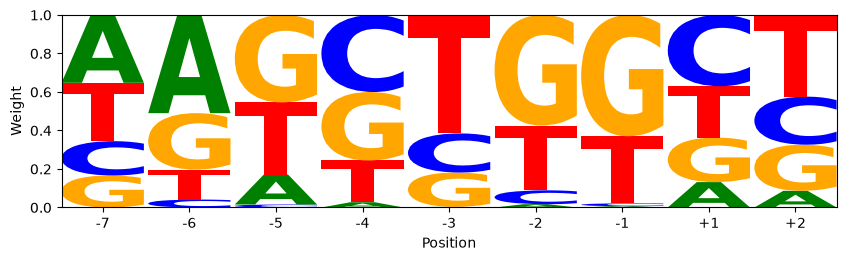

In [26]:
import logomaker
import matplotlib.pyplot as plt


weighted_matrix = pd.DataFrame(
    count_dicts,
    index=range(9)
).fillna(0)

weighted_matrix = weighted_matrix[["A", "C", "G", "T"]]

weighted_matrix = weighted_matrix.div(
    weighted_matrix.sum(axis=1),
    axis=0
)

# Create the logo object
logo = logomaker.Logo(weighted_matrix,
                      shade_below=0.5)

# Style the figure
logo.style_xticks(rotation=0, fmt='%d', anchor=0)
ax = logo.ax

positions = range(len(weighted_matrix)) 
custom_labels = ['-7', '-6', '-5', '-4', '-3', '-2', '-1', '+1', '+2'] 
ax.set_xticks(positions, labels=custom_labels)


ax.set_ylabel('Weight')
ax.set_xlabel('Position')

plt.show()

In [10]:
# Print entire dataset!

print(len(df))
with pd.option_context('display.max_rows', None, 'display.max_columns', None):
    display(df) 

1188


,oriTDB_accession,oriTDB_id,nic site,relaxase_family,relaxase_sequence,host,sDBM,sDBM_pos,sDBM_sim_gap,oriT_nic_seq
0,100001,GAATAAGGGACAGTGAAGAAGGAACACCCGCTCGCGGGTGGGCCTA...,60..61,TraI,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...,Pseudomonas aeruginosa,HVPMRSIKK,"(4, 12)","tensor(3.9850, device='cuda:0')",TATCCTGCC
1,100002,CCGGCCAGCCTCGCAGAGCAGGATTCCCGTTGAGCACCGCCAGGTG...,107..108,TraI,MIAKHVPMRSIKKSDFAELVKYITDEQGKTERLGHVRVTNCEANTL...,Klebsiella aerogenes K8841,HVPMRSIKK,"(4, 12)","tensor(3.9850, device='cuda:0')",TATCCTGCC
2,100003,CCAGTTTCTCGAAGAGAAACCGGTAAGTGCGCCCTCCC,31..32,MobA,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...,Escherichia coli,HLTAKTGSR,"(4, 12)","tensor(16.2991, device='cuda:0')",AAGTGCGCC
3,100004,TTGCCCTATCCTGCATCGC,13..14,TaxC,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...,E. coli,VEKDYRVKR,"(4, 12)","tensor(0.6425, device='cuda:0')",TATCCTGCA
4,100005,TTGCCCTATCCTGCATCGC,13..14,TaxC,MGVFVEKDYRVKRKSSENGRKSAFAHKVKNGGENYKKNVREKINRK...,E. coli,VEKDYRVKR,"(4, 12)","tensor(0.6425, device='cuda:0')",TATCCTGCA
5,100006,ATACGAAGTAACGAAGTTACTGCGTATAAGTGCGCCCT,34..35,TraA,MTIAKRENGKRSLIAMASYRSGEKLYSELYEKTNLYNHRTVKPEAF...,Streptococcus agalactiae B-49813/75,IAKRENGKR,"(2, 10)","tensor(0.4927, device='cuda:0')",AAGTGCGCC
6,100007,GGATTATCAATAGTCACATGTGAATCGGCCATTTATTTTATTAGAG...,305..306,TraI,MLSISSIKGDAGYYSHEDNYYASGSLDSRWMGEGAEKLGLKGEVAS...,Salmonella typhi,SISSIKGDA,"(2, 10)","tensor(2.7941, device='cuda:0')",CGGGTGTGG
7,100008,CCGCCTCGTCCTCCAAAAGTGCCTGCTTTTCCGGGCTTAGCCGTAC...,226..227,TrwC,MLSHMVLTRQDIGRAASYYEDGADDYYAKDGDASEWQGKGAEELGL...,Escherichia coli,SHMVLTRQD,"(2, 10)","tensor(0.3245, device='cuda:0')",ATTGTCTAT
8,100009,GGCCAGTTTCTCGAAGAGAAACCGGTAAATGCGCCCTCCCCTACAA...,33..34,MobA,MAIYHLTAKTGSRSGGQSARAKADYIQREGKYARDMDEVLHAESGH...,Pseudomonas aeruginosa,HLTAKTGSR,"(4, 12)","tensor(16.2991, device='cuda:0')",AAATGCGCC
9,100013,GTATTACCAAAGTAATAAAGCAAACTCATTATAAAACAATGAGTTA...,149..150,TraI,MLDITTITRQNVTSVVGYYSDAKDDYYSKDSSFTSWQGTGAEALGL...,Escherichia coli IncN,DITTITRQN,"(2, 10)","tensor(0.8588, device='cuda:0')",TAGGTGTAT


In [ ]:
final_df.to_csv('../data/processed/final_rep_virus_dataset.csv', index=False)